# 07 · Tuning P2: decision

What [`reports/method_research.md`](../reports/method_research.md) asked to tune: the cost-optimal Bayes rule saved the most but declined **6.7% of good customers**, because the assumed costs leave out churn and lifetime value. This notebook:
1. chooses the calibration method without looking at the test weeks;
2. adds a **cap on the good-customer decline rate** (default 1%, `costs.yaml`). It is enforced with a Lagrange penalty λ per declined good customer, so the rule becomes p·C_FN > (1−p)·(C_FP + λ). λ is set on the validation scoring half;
3. compares, at the **same** decline rate, the cost rule with a plain score threshold;
4. checks robustness over the cost grid and the review assumptions.

Scores come from the tuned model (notebook 06): the validation scoring half of weeks 16-19 (not used for early stopping) and the test weeks 20-26, which are used once.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.calibrate import expected_calibration_error, fit_isotonic, fit_platt
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET
from fraud.decision import (APPROVE, bayes_policy, good_decline_rate, load_costs, paired_cost_diff, penalty_for_cap,
                            policy_summary, realized_cost, three_action_policy, threshold_for_cap, threshold_policy)
from fraud.evaluate import summarize
from fraud.tuning import group_halves

FIG_DIR = Path("../reports/figures")
N_BOOT = 1000
scores = pd.read_parquet(PROCESSED_DIR / "scores_tuned.parquet")
valid, test = scores[scores["split"] == "valid_scoring_half"], scores[scores["split"] == "test"]
y_v, s_v, amt_v, day_v = (valid[c].to_numpy() for c in [TARGET, "score", "TransactionAmt", "day"])
y_t, s_t, amt_t, day_t = (test[c].to_numpy() for c in [TARGET, "score", "TransactionAmt", "day"])
amt_v, amt_t = amt_v.astype(float), amt_t.astype(float)
groups_t = test[ENTITY_COL]
costs = load_costs()
CAP = costs["constraints"]["max_good_decline_rate"]

# The validation half carries fewer transactions per day than live traffic: scale the review capacity for choices made on it.
per_day = lambda d: len(d) / d["day"].nunique()
costs_v = load_costs()
costs_v["manual_review"]["daily_capacity"] = int(round(costs["manual_review"]["daily_capacity"] * per_day(valid) / per_day(test)))
print(f"validation scoring half: {len(valid):,} rows ({y_v.mean():.2%} fraud); test: {len(test):,} rows ({y_t.mean():.2%} fraud)")
print(f"review capacity: {costs['manual_review']['daily_capacity']}/day on test, {costs_v['manual_review']['daily_capacity']}/day on the validation half")

validation scoring half: 41,756 rows (3.91% fraud); test: 121,163 rows (3.45% fraud)
review capacity: 200/day on test, 106/day on the validation half


## 1. Calibration method, chosen by cross-fitting inside the validation half

In [2]:
half = group_halves(valid[ENTITY_COL], seed=1)
oof = {}
for name, fitter in [("platt", fit_platt), ("isotonic", fit_isotonic)]:
    p = np.empty(len(s_v))
    for fit_mask in (half, ~half):
        p[~fit_mask] = fitter(s_v[fit_mask], y_v[fit_mask])(s_v[~fit_mask])
    oof[name] = p
cal_choice = pd.DataFrame({name: {"oof_log_loss": summarize(y_v, p)["log_loss"], "oof_ece": expected_calibration_error(y_v, p)}
                           for name, p in oof.items()}).T
method = cal_choice["oof_log_loss"].idxmin()
calibrate = {"platt": fit_platt, "isotonic": fit_isotonic}[method](s_v, y_v)
p_t = calibrate(s_t)
p_v = oof[method]  # out-of-fold probabilities for every choice below
print(f"chosen calibration: {method}; test log loss {summarize(y_t, p_t)['log_loss']:.4f}, ECE {expected_calibration_error(y_t, p_t):.4f}")
cal_choice.round(4)

chosen calibration: platt; test log loss 0.0899, ECE 0.0023


,oof_log_loss,oof_ece
platt,0.0802,0.0020
isotonic,0.0823,0.0026


## 2. Policies with a cap on declined good customers

In [3]:
policies = {
    "approve all": np.full(len(s_t), APPROVE),
    "threshold 0.5 (before)": threshold_policy(s_t, 0.5),
    "Bayes, no cap (method research)": bayes_policy(p_t, amt_t, costs),
    "3-action, no cap": three_action_policy(p_t, amt_t, day_t, costs),
}
chosen = {}
for cap in costs["constraints"]["report_caps"]:
    thr = threshold_for_cap(s_v, y_v, cap)
    lam = penalty_for_cap(lambda l: bayes_policy(p_v, amt_v, costs, fp_penalty=l), y_v, cap)
    lam3 = penalty_for_cap(lambda l: three_action_policy(p_v, amt_v, day_v, costs_v, fp_penalty=l), y_v, cap)
    chosen[cap] = {"score_threshold": thr, "bayes_lambda": lam, "three_action_lambda": lam3}
    policies[f"score threshold, cap {cap:.1%}"] = threshold_policy(s_t, thr)
    policies[f"Bayes, cap {cap:.1%}"] = bayes_policy(p_t, amt_t, costs, fp_penalty=lam)
    policies[f"3-action, cap {cap:.1%}"] = three_action_policy(p_t, amt_t, day_t, costs, fp_penalty=lam3)
print("settings chosen on the validation half:", {f"{k:.1%}": {n: round(v, 4) for n, v in d.items()} for k, d in chosen.items()})

cost = {name: realized_cost(a, y_t, amt_t, costs) for name, a in policies.items()}
rows = []
for name, a in policies.items():
    saving = paired_cost_diff(cost[name], cost["approve all"], groups_t, N_BOOT)
    rows.append({"policy": name, **policy_summary(a, y_t, amt_t, costs),
                 "saving": saving.estimate, "saving_low": saving.low, "saving_high": saving.high})
table = pd.DataFrame(rows).set_index("policy")
table[["total_cost", "saving", "saving_low", "saving_high", "good_customers_declined", "declined_share", "reviewed_share", "fraud_usd_stopped"]].round(4)

settings chosen on the validation half: {'0.5%': {'score_threshold': 0.1155, 'bayes_lambda': 123.2388, 'three_action_lambda': 14.9225}, '1.0%': {'score_threshold': 0.0293, 'bayes_lambda': 47.2904, 'three_action_lambda': 5.6684}, '2.0%': {'score_threshold': 0.0093, 'bayes_lambda': 17.531, 'three_action_lambda': 0.9742}}


,total_cost,saving,saving_low,saving_high,good_customers_declined,declined_share,reviewed_share,fraud_usd_stopped
policy,,,,,,,,
approve all,688583.0907,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000
threshold 0.5 (before),540755.5316,147827.5591,129997.5006,165734.5344,0.0021,0.0132,0.000,0.2069
"Bayes, no cap (method research)",295397.0060,393186.0847,336846.2487,455114.0285,0.0619,0.0830,0.000,0.7124
"3-action, no cap",201888.9809,486694.1098,427168.4662,552005.5568,0.0315,0.0503,0.071,0.8022
"score threshold, cap 0.5%",482612.1156,205970.9750,178106.9255,235989.1823,0.0055,0.0193,0.000,0.2984
"Bayes, cap 0.5%",425843.8286,262739.2621,222462.5345,311595.9590,0.0056,0.0181,0.000,0.4041
"3-action, cap 0.5%",216735.5610,471847.5296,416569.5750,534097.8524,0.0061,0.0200,0.071,0.7475
"score threshold, cap 1.0%",422964.7469,265618.3437,230118.2385,307017.2138,0.0119,0.0280,0.000,0.3996
"Bayes, cap 1.0%",378608.7281,309974.3625,263298.1018,364854.3972,0.0117,0.0266,0.000,0.4936


In [4]:
print("At the same cap, cost rule vs score threshold (negative = the cost rule is cheaper), 95% CI over card holders:")
for cap in costs["constraints"]["report_caps"]:
    for rule in ["Bayes", "3-action"]:
        d = paired_cost_diff(cost[f"score threshold, cap {cap:.1%}"], cost[f"{rule}, cap {cap:.1%}"], groups_t, N_BOOT)
        print(f"  cap {cap:.1%}: {rule:8s} - threshold = {d.estimate:>10,.0f} ({d.low:,.0f}, {d.high:,.0f})")

At the same cap, cost rule vs score threshold (negative = the cost rule is cheaper), 95% CI over card holders:


  cap 0.5%: Bayes    - threshold =    -56,768 (-83,855, -33,397)


  cap 0.5%: 3-action - threshold =   -265,877 (-313,591, -223,063)


  cap 1.0%: Bayes    - threshold =    -44,356 (-69,830, -22,408)


  cap 1.0%: 3-action - threshold =   -212,401 (-251,932, -174,030)


  cap 2.0%: Bayes    - threshold =    -48,430 (-68,766, -27,764)


  cap 2.0%: 3-action - threshold =   -178,697 (-213,194, -145,391)


## 3. Cost vs good-customer decline rate (illustration on the test weeks; nothing is chosen from it)

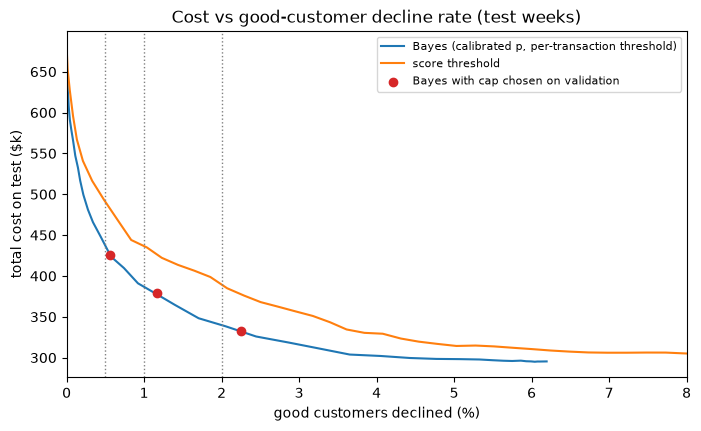

In [5]:
frontier = []
for lam in np.r_[0, np.logspace(-1, 4, 40)]:
    a = bayes_policy(p_t, amt_t, costs, fp_penalty=lam)
    frontier.append({"rule": "Bayes (calibrated p, per-transaction threshold)", "good_declined": good_decline_rate(a, y_t), "cost": realized_cost(a, y_t, amt_t, costs).sum()})
for q in np.linspace(0.85, 0.9995, 60):
    a = threshold_policy(s_t, np.quantile(s_t, q))
    frontier.append({"rule": "score threshold", "good_declined": good_decline_rate(a, y_t), "cost": realized_cost(a, y_t, amt_t, costs).sum()})
frontier = pd.DataFrame(frontier)

fig, ax = plt.subplots(figsize=(8, 4.5))
for rule, g in frontier.groupby("rule"):
    g = g.sort_values("good_declined")
    ax.plot(g["good_declined"] * 100, g["cost"] / 1e3, label=rule)
for cap in costs["constraints"]["report_caps"]:
    ax.axvline(cap * 100, color="gray", ls=":", lw=1)
ax.scatter(table.loc[[f"Bayes, cap {c:.1%}" for c in chosen], "good_customers_declined"] * 100,
           table.loc[[f"Bayes, cap {c:.1%}" for c in chosen], "total_cost"] / 1e3, color="C3", zorder=5, label="Bayes with cap chosen on validation")
ax.set(xlim=(0, 8), xlabel="good customers declined (%)", ylabel="total cost on test ($k)", title="Cost vs good-customer decline rate (test weeks)")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "tu_frontier.png", dpi=120, bbox_inches="tight")

## 4. Robustness: cost grid (cap 1%) and review assumptions

Bayes at cap 1% saves vs the score threshold at the same cap in 30 of 30 cost scenarios


margin_share,0.00,0.01,0.03,0.05,0.10
fp_fixed,,,,,
1,64.0,56.0,44.0,40.0,23.0
2,64.0,56.0,44.0,40.0,23.0
5,64.0,56.0,44.0,40.0,23.0
10,64.0,56.0,44.0,40.0,24.0
20,64.0,56.0,45.0,40.0,24.0
50,64.0,56.0,45.0,42.0,28.0


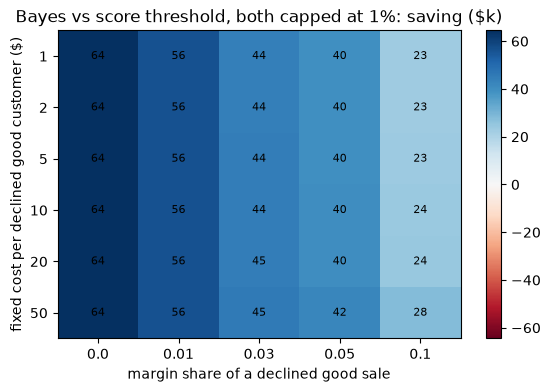

In [6]:
grid = costs["sensitivity"]
cells = []
for fp_fixed in grid["fp_fixed_grid"]:
    for margin in grid["margin_share_grid"]:
        c = load_costs(fp_fixed=fp_fixed, margin_share=margin)
        lam = penalty_for_cap(lambda l: bayes_policy(p_v, amt_v, c, fp_penalty=l), y_v, CAP)
        thr_cost = realized_cost(threshold_policy(s_t, chosen[CAP]["score_threshold"]), y_t, amt_t, c).sum()
        bayes_cost = realized_cost(bayes_policy(p_t, amt_t, c, fp_penalty=lam), y_t, amt_t, c).sum()
        cells.append({"fp_fixed": fp_fixed, "margin_share": margin, "bayes_saving_vs_threshold": thr_cost - bayes_cost})
sens = pd.DataFrame(cells)
m = sens.pivot(index="fp_fixed", columns="margin_share", values="bayes_saving_vs_threshold") / 1e3
print(f"Bayes at cap {CAP:.0%} saves vs the score threshold at the same cap in {int((m > 0).to_numpy().sum())} of {m.size} cost scenarios")
fig, ax = plt.subplots(figsize=(6.5, 4))
lim = np.abs(m.to_numpy()).max()
im = ax.imshow(m, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(m.shape[1]), m.columns)
ax.set_yticks(range(m.shape[0]), m.index)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.annotate(f"{m.iat[i, j]:.0f}", (j, i), ha="center", va="center", fontsize=8)
ax.set(xlabel="margin share of a declined good sale", ylabel="fixed cost per declined good customer ($)",
       title=f"Bayes vs score threshold, both capped at {CAP:.0%}: saving ($k)")
fig.colorbar(im, ax=ax)
fig.savefig(FIG_DIR / "tu_cost_sensitivity_capped.png", dpi=120, bbox_inches="tight")
m.round(0)

In [7]:
rows = []
bayes_cap_cost = cost[f"Bayes, cap {CAP:.1%}"].sum()
for review_cost in [1.0, 3.0, 10.0]:
    for catch in [0.7, 0.9, 1.0]:
        c, cv = load_costs(), load_costs()
        for x in (c, cv):
            x["manual_review"]["cost_per_case"], x["manual_review"]["catch_rate"] = review_cost, catch
        cv["manual_review"]["daily_capacity"] = costs_v["manual_review"]["daily_capacity"]
        lam3 = penalty_for_cap(lambda l: three_action_policy(p_v, amt_v, day_v, cv, fp_penalty=l), y_v, CAP)
        a = three_action_policy(p_t, amt_t, day_t, c, fp_penalty=lam3)
        rows.append({"review_cost": review_cost, "catch_rate": catch,
                     "3-action saving vs Bayes (cap 1%)": bayes_cap_cost - realized_cost(a, y_t, amt_t, c).sum(),
                     "good_declined": good_decline_rate(a, y_t)})
pd.DataFrame(rows).round(4)

,review_cost,catch_rate,3-action saving vs Bayes (cap 1%),good_declined
0,1.0,0.7,137973.3683,0.0118
1,1.0,0.9,185245.0374,0.0122
2,1.0,1.0,216909.9228,0.0121
3,3.0,0.7,120773.3683,0.0118
4,3.0,0.9,168045.0374,0.0122
5,3.0,1.0,199709.9228,0.0121
6,10.0,0.7,64662.5885,0.0109
7,10.0,0.9,105710.4919,0.0114
8,10.0,1.0,133084.6709,0.0105
